In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import sklearn

In [2]:
import pandas as pd
df = pd.read_csv('https://raw.githubusercontent.com/anvarnarz/praktikum_datasets/main/housing_data_08-02-2021.csv')
df.head()

,location,district,rooms,size,level,max_levels,price
0,"город Ташкент, Юнусабадский район, Юнусабад 8-...",Юнусабадский,3,57,4,4,52000
1,"город Ташкент, Яккасарайский район, 1-й тупик ...",Яккасарайский,2,52,4,5,56000
2,"город Ташкент, Чиланзарский район, Чиланзар 2-...",Чиланзарский,2,42,4,4,37000
3,"город Ташкент, Чиланзарский район, Чиланзар 9-...",Чиланзарский,3,65,1,4,49500
4,"город Ташкент, Чиланзарский район, площадь Актепа",Чиланзарский,3,70,3,5,55000


# Ustunlar ta'rifi
- `location` - sotilayotgan uy manzili
- `district` - uy joylashgan tuman
- `rooms` - xonalar soni
- `size` - uy maydoni (kv.m)
- `level` - uy joylashgan qavat
- `max_levels` - ja'mi qavatlar soni
- `price` - uy narxi

## Vazifani CRSIP-DM Metolodgiyasi yordamida bajaring.
<img src="https://i.imgur.com/dzZnnYi.png" alt="CRISP-DM" width="800"/>

# data engenering

In [3]:
print(df.sample(2))
df.describe()

                                             location      district  rooms  \
6695  город Ташкент, Олмазорский район, Каракамыш 2/4   Олмазорский      2   
5513   город Ташкент, Чиланзарский район, Чиланзар-17  Чиланзарский      3   

     size  level  max_levels  price  
6695   58      2           4  39500  
5513   67      4           4  34500  


,rooms,level,max_levels
count,7565.000000,7565.000000,7565.000000
mean,2.625644,3.699273,6.038202
std,1.085201,2.237275,2.613271
min,1.000000,1.000000,1.000000
25%,2.000000,2.000000,4.000000
50%,3.000000,3.000000,5.000000
75%,3.000000,5.000000,9.000000
max,10.000000,19.000000,25.000000


In [4]:
df.head()

,location,district,rooms,size,level,max_levels,price
0,"город Ташкент, Юнусабадский район, Юнусабад 8-...",Юнусабадский,3,57,4,4,52000
1,"город Ташкент, Яккасарайский район, 1-й тупик ...",Яккасарайский,2,52,4,5,56000
2,"город Ташкент, Чиланзарский район, Чиланзар 2-...",Чиланзарский,2,42,4,4,37000
3,"город Ташкент, Чиланзарский район, Чиланзар 9-...",Чиланзарский,3,65,1,4,49500
4,"город Ташкент, Чиланзарский район, площадь Актепа",Чиланзарский,3,70,3,5,55000


In [5]:
df.isnull().sum()

location      0
district      0
rooms         0
size          0
level         0
max_levels    0
price         0
dtype: int64

In [14]:
df_number = df[['rooms', 'size', 'level','max_levels', 'price']]

In [7]:
df_number

,rooms,size,level,max_levels,price
0,3,57,4,4,52000
1,2,52,4,5,56000
2,2,42,4,4,37000
3,3,65,1,4,49500
4,3,70,3,5,55000
...,...,...,...,...,...
7560,1,38,5,5,24500
7561,2,49,1,4,32000
7562,2,64,3,9,40000
7563,1,18,1,4,11000


# data object to int

In [8]:
df['price'] = df['price'].str.replace('Договорная', '0').astype(int)

In [9]:
df['size'] = df['size'].str.replace('Площадьземли:1сот', '0').astype(float)

In [13]:
df['size']

0       57.0
1       52.0
2       42.0
3       65.0
4       70.0
        ... 
7560    38.0
7561    49.0
7562    64.0
7563    18.0
7564    30.0
Name: size, Length: 7565, dtype: float64

In [18]:
df_number

,rooms,size,level,max_levels,price
0,3,57.0,4,4,52000
1,2,52.0,4,5,56000
2,2,42.0,4,4,37000
3,3,65.0,1,4,49500
4,3,70.0,3,5,55000
...,...,...,...,...,...
7560,1,38.0,5,5,24500
7561,2,49.0,1,4,32000
7562,2,64.0,3,9,40000
7563,1,18.0,1,4,11000


# data vizualization

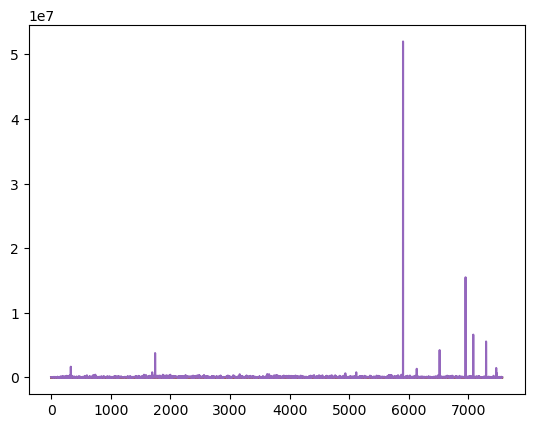

In [22]:
plt.plot(df_number)

<Axes: xlabel='price', ylabel='level'>

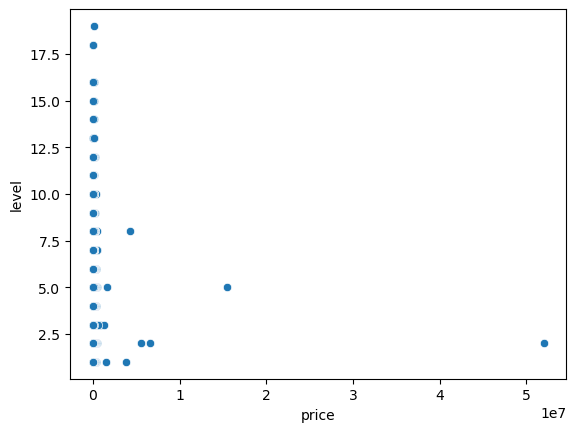

In [24]:
sns.scatterplot(data=df_number, x='price', y='level')

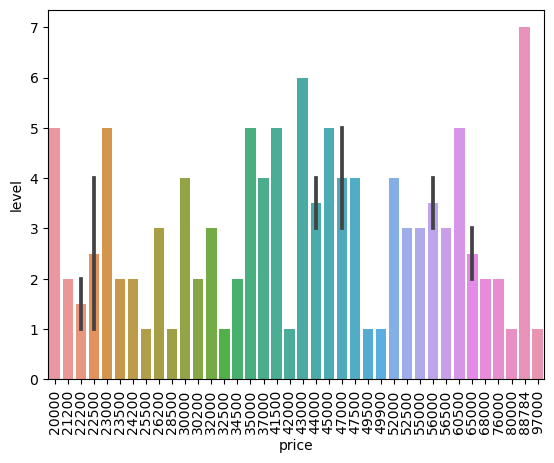

In [28]:
sns.barplot(data=df_number[:50], x='price', y='level')
plt.xticks(rotation=90)
plt.show()

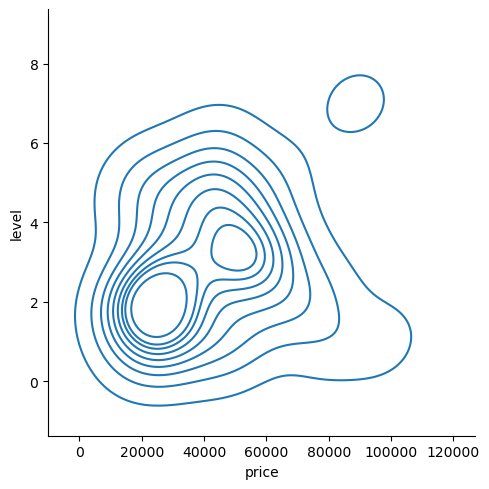

In [31]:
sns.displot(data=df_number[:50], x='price', y='level', kind='kde')


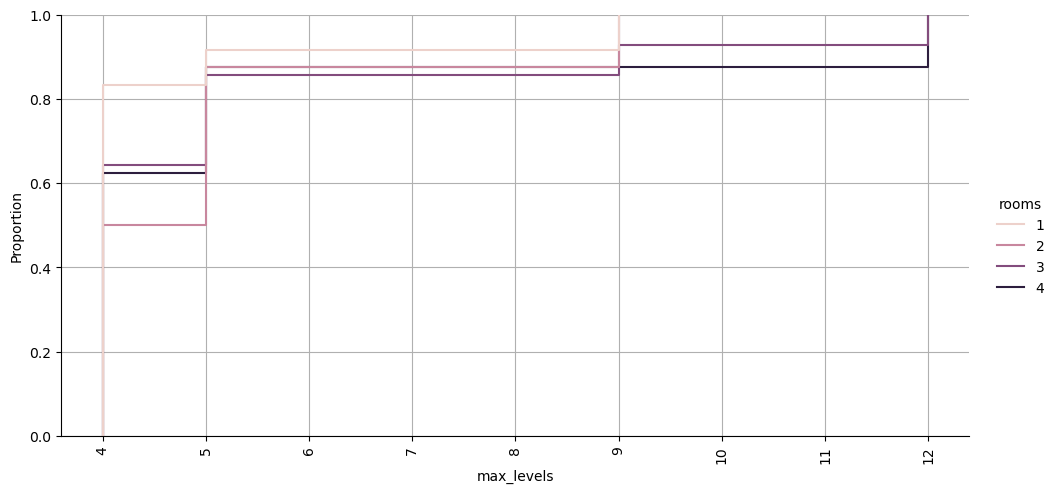

In [41]:
sns.displot(data=df_number[:50], x="max_levels", hue="rooms", kind="ecdf", height=5, aspect=2)
plt.xticks(rotation=90)
plt.grid()
plt.show()

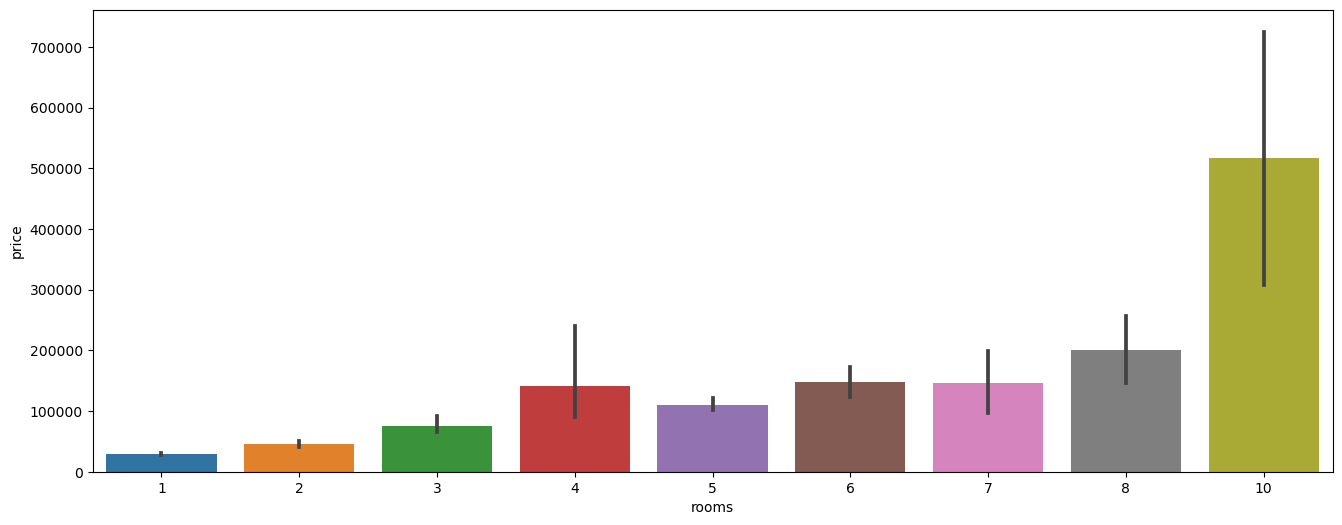

In [40]:
plt.figure(figsize=(16,6))
sns.barplot(x=df['rooms'], y=df['price'])
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

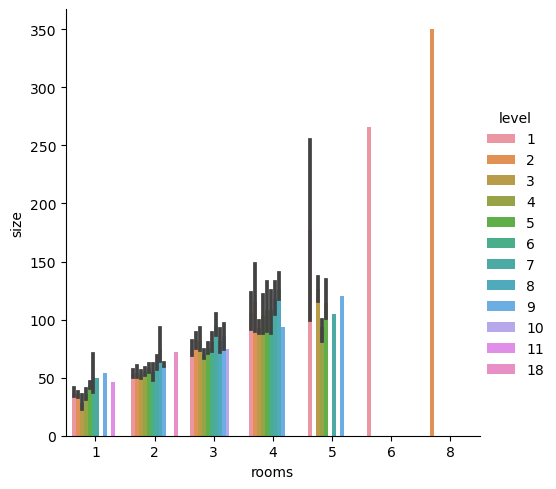

In [48]:
sns.catplot(data=df_number[:500], kind="bar", x="rooms", y="size", hue="level")
plt.show

/Users/azamatergashev/anaconda3/envs/tensorflow/lib/python3.10/site-packages/seaborn/categorical.py:3544: UserWarning: 99.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/azamatergashev/anaconda3/envs/tensorflow/lib/python3.10/site-packages/seaborn/categorical.py:3544: UserWarning: 99.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/azamatergashev/anaconda3/envs/tensorflow/lib/python3.10/site-packages/seaborn/categorical.py:3544: UserWarning: 99.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/azamatergashev/anaconda3/envs/tensorflow/lib/python3.10/site-packages/seaborn/categorical.py:3544: UserWarning: 99.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  

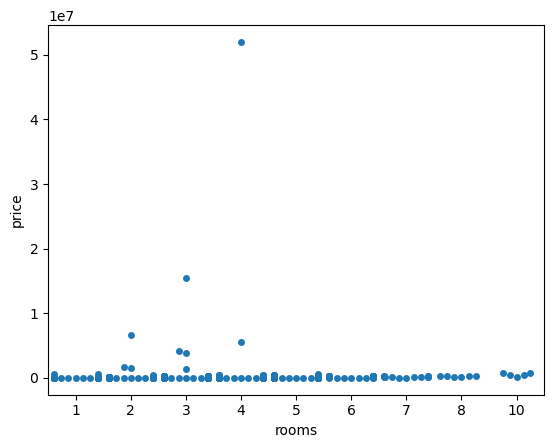

In [49]:
sns.swarmplot(data=df, x=df['rooms'], y=df['price'])
plt.show()

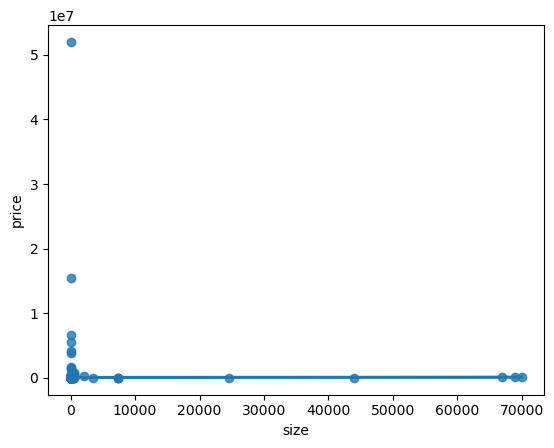

In [52]:
sns.regplot(data=df, x='size', y='price')
plt.show()

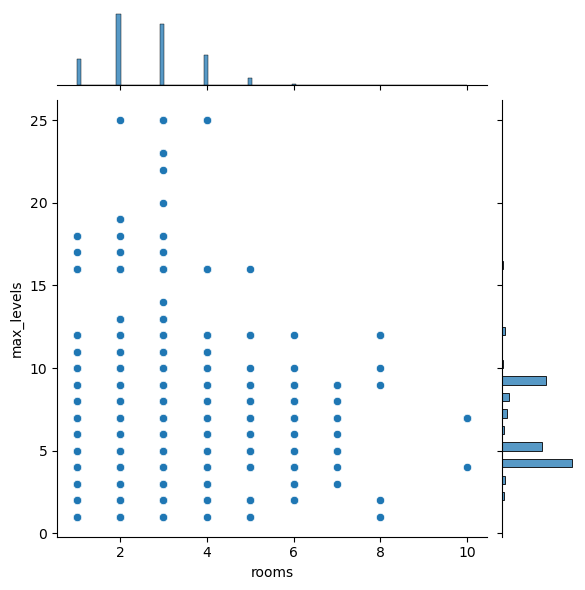

In [56]:
sns.jointplot(data=df_number, x='rooms', y='max_levels')